In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
DAY03 = ROOT.parent / "day03_polygons"

PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

peaks = gpd.read_file(
    DAY03 / "data" / "processed" / "peaks_with_ridges.gpkg"
)

# Используем метрическую проекцию
peaks = peaks.to_crs("EPSG:32642")

assert len(peaks) == 1302
assert peaks["id"].is_unique

print("Peaks:", len(peaks))
print("CRS:", peaks.crs)

display(peaks.head())

Peaks: 1302
CRS: EPSG:32642


C:\Users\m.maxsudov\30daymapchallenge-2026\.venv\Lib\site-packages\pyogrio\geopandas.py:382: UserWarning: More than one layer found in 'peaks_with_ridges.gpkg': 'peaks_with_ridges' (default), 'peaks'. Specify layer parameter to avoid this warning.
  result = read_func(


,id,lon,lat,tags,visible,version,timestamp,changeset,natural,name,...,inside_tashkent,peak_name,index_right,ridge_id,ridge_name,ridge_count,assignment_status,original_status,assignment_method,geometry
0,2576624309,69.775973,41.698082,"{""man_made"":""survey_point""}",True,3,1637085386,0.0,peak,NaN,...,True,Unnamed,0.0,1174.0,Каржантау,1,ASSIGNED,ASSIGNED,SPATIAL_JOIN,POINT (564567.384 4616546.377)
1,2576624319,69.875838,41.701620,NaN,True,3,1769125218,0.0,peak,Дипломат,...,True,Дипломат,0.0,1174.0,Каржантау,1,ASSIGNED,ASSIGNED,SPATIAL_JOIN,POINT (572873.052 4617018.878)
2,2576679427,69.811340,41.677978,NaN,True,1,1386835816,0.0,peak,NaN,...,True,Unnamed,0.0,1174.0,Каржантау,1,ASSIGNED,ASSIGNED,SPATIAL_JOIN,POINT (567531.247 4614341.467)
3,2576679434,69.727058,41.692924,NaN,True,1,1386835816,0.0,peak,NaN,...,True,Unnamed,0.0,1174.0,Каржантау,1,ASSIGNED,ASSIGNED,SPATIAL_JOIN,POINT (560502.06 4615938.223)
4,2576749848,69.818875,41.694221,NaN,True,4,1680167080,0.0,peak,NaN,...,True,Unnamed,0.0,1174.0,Каржантау,1,ASSIGNED,ASSIGNED,SPATIAL_JOIN,POINT (568141.221 4616150.731)


In [2]:
X_xy = np.column_stack([
    peaks.geometry.x.to_numpy(),
    peaks.geometry.y.to_numpy()
])

print("Feature matrix:", X_xy.shape)
print("X range:", X_xy[:, 0].min(), X_xy[:, 0].max())
print("Y range:", X_xy[:, 1].min(), X_xy[:, 1].max())

Feature matrix: (1302, 2)
X range: 556596.6725946458 687346.8606640942
Y range: 4497735.39192955 4684582.091144082


### Experiments with DBSCAN

In [4]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=5000,       # 5 км
    min_samples=5,
    metric="euclidean"
)

labels = dbscan.fit_predict(X_xy)

peaks["cluster_dbscan"] = labels

n_clusters = len(set(labels) - {-1})
n_noise = np.sum(labels == -1)

print("Clusters:", n_clusters)
print("Noise points:", n_noise)
print("Noise share:", round(n_noise / len(peaks) * 100, 1), "%")

Clusters: 5
Noise points: 0
Noise share: 0.0 %


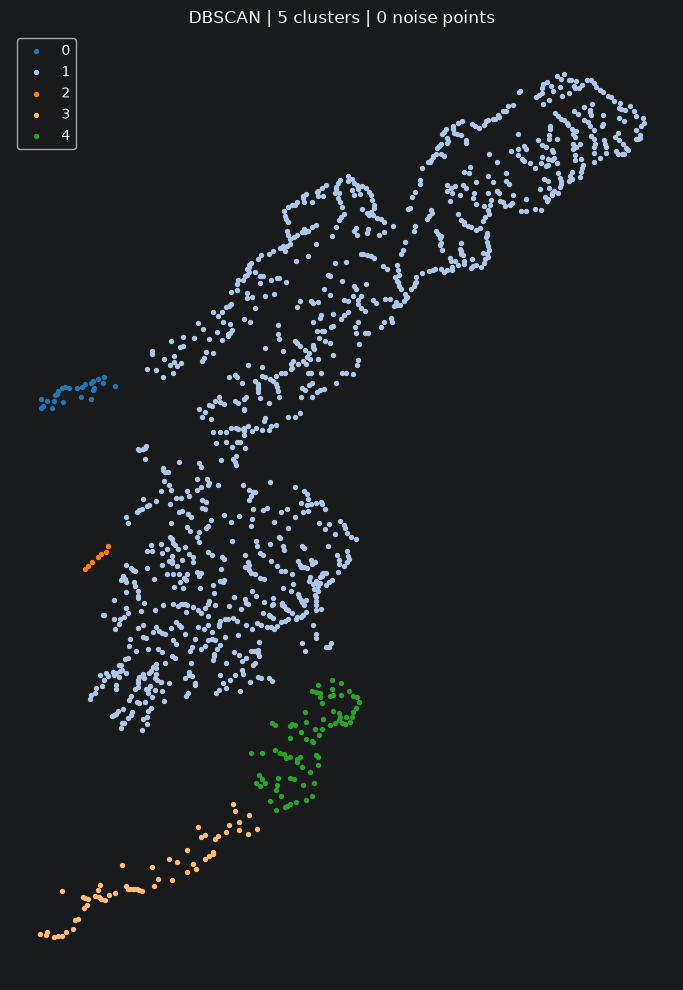

In [5]:
fig, ax = plt.subplots(figsize=(11, 10))

peaks.plot(
    ax=ax,
    column="cluster_dbscan",
    categorical=True,
    legend=True,
    markersize=8,
    cmap="tab20"
)

ax.set_title(
    f"DBSCAN | {n_clusters} clusters | "
    f"{n_noise} noise points"
)

ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [6]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

results = []

for eps_km in [0.5, 1, 1.5, 2, 2.5, 3, 4, 5]:
    for min_samples in [3, 5, 8]:
        labels = DBSCAN(
            eps=eps_km * 1000,
            min_samples=min_samples
        ).fit_predict(X_xy)

        results.append({
            "eps_km": eps_km,
            "min_samples": min_samples,
            "clusters": len(set(labels) - {-1}),
            "noise_pct": round(
                np.mean(labels == -1) * 100, 1
            ),
            "largest_cluster_pct": round(
                max(
                    (
                        np.sum(labels == c)
                        for c in set(labels) if c != -1
                    ),
                    default=0
                ) / len(labels) * 100, 1
            )
        })

dbscan_results = pd.DataFrame(results)

display(dbscan_results)

,eps_km,min_samples,clusters,noise_pct,largest_cluster_pct
0,0.5,3,7,98.3,0.3
1,0.5,5,0,100.0,0.0
2,0.5,8,0,100.0,0.0
3,1.0,3,122,64.1,0.7
4,1.0,5,3,98.8,0.4
5,1.0,8,0,100.0,0.0
6,1.5,3,135,30.3,1.9
7,1.5,5,43,77.6,1.4
8,1.5,8,1,99.4,0.6
9,2.0,3,97,14.7,7.4


### Experiment with HDBSCAN

In [7]:
from sklearn.cluster import HDBSCAN

hdbscan = HDBSCAN(
    min_cluster_size=15,
    min_samples=5,
    cluster_selection_method="leaf"
)

labels_hdb = hdbscan.fit_predict(X_xy)

peaks["cluster_hdbscan"] = labels_hdb

print("Clusters:", len(set(labels_hdb) - {-1}))
print("Noise:", (labels_hdb == -1).sum())

Clusters: 29
Noise: 471


C:\Users\m.maxsudov\30daymapchallenge-2026\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


### Terrain-aware Clustering

In [10]:
from sklearn.neighbors import NearestNeighbors
import networkx as nx
import numpy as np

k = 8

nn = NearestNeighbors(
    n_neighbors=k + 1,
    metric="euclidean"
)

nn.fit(X_xy)
distances, indices = nn.kneighbors(X_xy)

# Создаём граф заново!
G = nx.Graph()
G.add_nodes_from(range(len(X_xy)))

for i in range(len(X_xy)):
    for j, dist in zip(
        indices[i, 1:],
        distances[i, 1:]
    ):
        j = int(j)

        if i != j and dist <= 12000:
            G.add_edge(
                i,
                j,
                distance_m=float(dist)
            )

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Connected components:", nx.number_connected_components(G))

Nodes: 1302
Edges: 6127
Connected components: 2


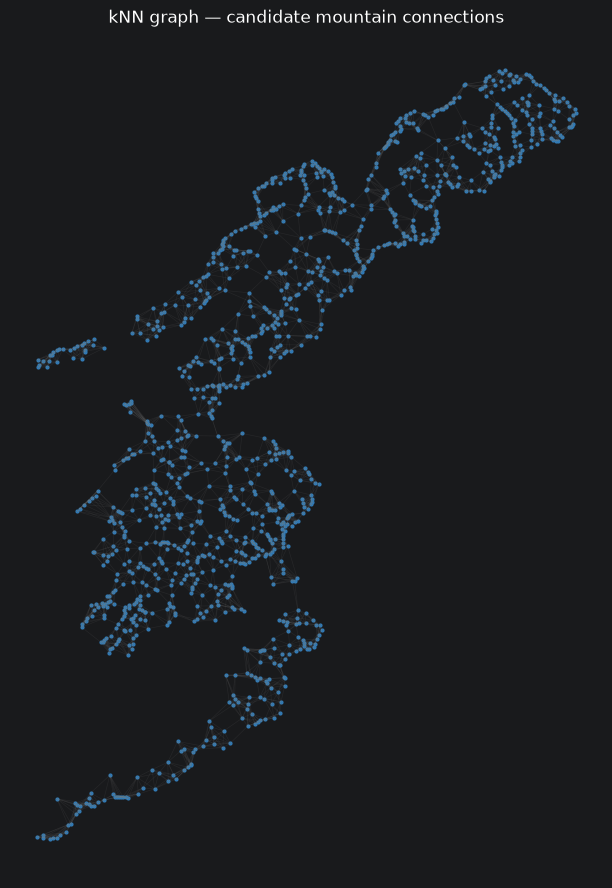

In [11]:
fig, ax = plt.subplots(figsize=(11, 11))

for u, v in G.edges():
    ax.plot(
        [X_xy[u, 0], X_xy[v, 0]],
        [X_xy[u, 1], X_xy[v, 1]],
        color="gray",
        alpha=0.12,
        linewidth=0.5
    )

ax.scatter(
    X_xy[:, 0],
    X_xy[:, 1],
    s=4,
    color="#327AB5"
)

ax.set_title("kNN graph — candidate mountain connections")
ax.set_aspect("equal")
ax.axis("off")

plt.show()

In [14]:
import rasterio
import numpy as np
import pandas as pd

DEM_DIR = (
    ROOT.parent / "day02_lines"
    / "data" / "raw" / "dem"
)

dem_files = sorted(DEM_DIR.glob("*.tif"))

assert dem_files, "DEM tiles not found"

print(f"Available DEM tiles: {len(dem_files)}")

Available DEM tiles: 84


In [15]:
edge_profiles = {}
all_coords = []
cursor = 0

for u, v in G.edges():
    p1 = X_xy[u]
    p2 = X_xy[v]

    distance = np.linalg.norm(p2 - p1)
    n = max(2, int(np.ceil(distance / 100)) + 1)

    coords = np.column_stack([
        np.linspace(p1[0], p2[0], n),
        np.linspace(p1[1], p2[1], n)
    ])

    edge_profiles[(u, v)] = slice(cursor, cursor + n)
    all_coords.append(coords)
    cursor += n

all_coords = np.vstack(all_coords)

print("Edges:", len(edge_profiles))
print("DEM sample points:", len(all_coords))

Edges: 6127
DEM sample points: 176151


In [16]:
from pyproj import Transformer

elevations = np.full(len(all_coords), np.nan)

for dem_file in dem_files:
    with rasterio.open(dem_file) as src:
        transformer = Transformer.from_crs(
            "EPSG:32642",
            src.crs,
            always_xy=True
        )

        xs, ys = transformer.transform(
            all_coords[:, 0],
            all_coords[:, 1]
        )

        # Выбираем точки внутри тайла
        mask = (
            (xs >= src.bounds.left)
            & (xs < src.bounds.right)
            & (ys > src.bounds.bottom)
            & (ys <= src.bounds.top)
            & np.isnan(elevations)
        )

        idx = np.flatnonzero(mask)

        if len(idx) == 0:
            continue

        coords = zip(xs[idx], ys[idx])

        samples = src.sample(coords, masked=True)

        for point_idx, sample in zip(idx, samples):
            value = sample[0]

            if not np.ma.is_masked(value) and np.isfinite(value):
                elevations[point_idx] = float(value)

print(
    "DEM sample coverage:",
    round(np.isfinite(elevations).mean() * 100, 2),
    "%"
)

DEM sample coverage: 100.0 %


In [17]:
for (u, v), sl in edge_profiles.items():
    profile = elevations[sl]

    # Не рассчитываем глубину по неполному профилю
    if not np.isfinite(profile).all():
        G[u][v]["valley_depth_m"] = np.nan
        continue

    endpoint_min = min(profile[0], profile[-1])
    valley_bottom = profile.min()

    G[u][v]["valley_depth_m"] = max(
        0.0,
        float(endpoint_min - valley_bottom)
    )

In [18]:
valley_depths = pd.Series([
    d["valley_depth_m"]
    for _, _, d in G.edges(data=True)
])

display(
    valley_depths.describe(
        percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
    )
)

print("Missing profiles:", valley_depths.isna().sum())

count    6127.000000
mean      260.260476
std       214.950329
min         0.000000
25%       100.085327
50%       205.274414
75%       359.786255
90%       541.188110
95%       681.775073
max      1399.194580
dtype: float64

Missing profiles: 0


#### Анализ глубины долин

In [19]:
edges_df = pd.DataFrame([
    {
        "u": u,
        "v": v,
        "distance_km": d["distance_m"] / 1000,
        "valley_depth_m": d["valley_depth_m"]
    }
    for u, v, d in G.edges(data=True)
])

display(
    edges_df[
        ["distance_km", "valley_depth_m"]
    ].describe(percentiles=[.25, .5, .75, .9, .95, .99]).round(1)
)

print("Edges with valley depth >500 m:",
      (edges_df["valley_depth_m"] > 500).sum())

print("Edges with valley depth >1000 m:",
      (edges_df["valley_depth_m"] > 1000).sum())

,distance_km,valley_depth_m
count,6127.0,6127.0
mean,2.7,260.3
std,1.3,215.0
min,0.0,0.0
25%,1.8,100.1
50%,2.7,205.3
75%,3.5,359.8
90%,4.4,541.2
95%,5.0,681.8
99%,6.2,1035.2


Edges with valley depth >500 m: 767
Edges with valley depth >1000 m: 75


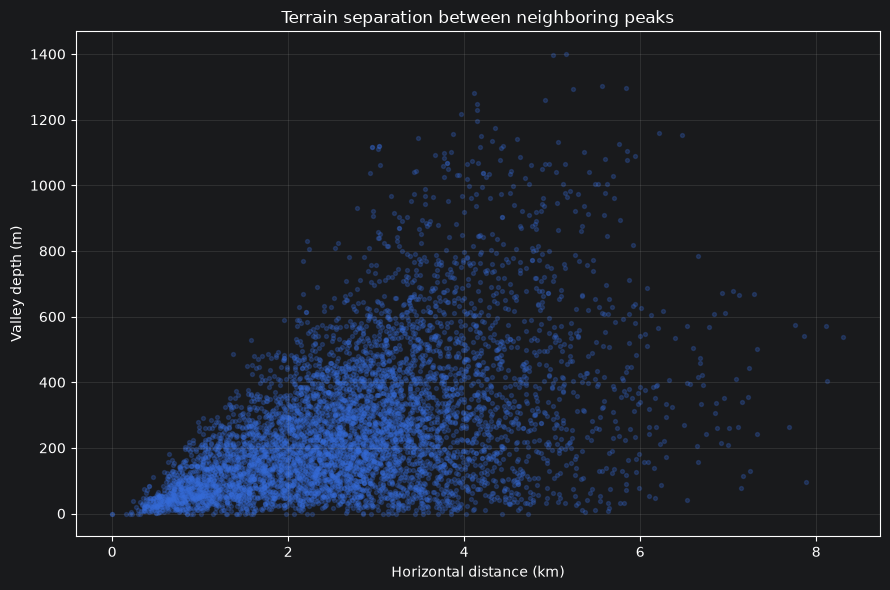

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    edges_df["distance_km"],
    edges_df["valley_depth_m"],
    s=8,
    alpha=0.25
)

ax.set_xlabel("Horizontal distance (km)")
ax.set_ylabel("Valley depth (m)")
ax.set_title("Terrain separation between neighboring peaks")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

#### Создание графов

In [21]:
sigma_d = edges_df["distance_km"].median()
sigma_v = edges_df.loc[
    edges_df["valley_depth_m"] > 0,
    "valley_depth_m"
].median()

print("Distance scale:", sigma_d, "km")
print("Valley depth scale:", sigma_v, "m")

assert sigma_d > 0
assert np.isfinite(sigma_v) and sigma_v > 0

G_spatial = G.copy()
G_terrain = G.copy()

for u, v, d in G.edges(data=True):
    distance_km = d["distance_m"] / 1000
    valley_depth = d["valley_depth_m"]

    spatial_weight = np.exp(-distance_km / sigma_d)

    terrain_weight = (
        spatial_weight
        * np.exp(-valley_depth / sigma_v)
    )

    G_spatial[u][v]["weight"] = float(spatial_weight)
    G_terrain[u][v]["weight"] = float(terrain_weight)

Distance scale: 2.6603060771235176 km
Valley depth scale: 206.512451171875 m


In [22]:
import networkx as nx

resolution = 1.0

spatial_communities = nx.community.louvain_communities(
    G_spatial,
    weight="weight",
    resolution=resolution,
    seed=42
)

terrain_communities = nx.community.louvain_communities(
    G_terrain,
    weight="weight",
    resolution=resolution,
    seed=42
)

def communities_to_labels(communities, n_nodes):
    labels = np.full(n_nodes, -1, dtype=int)

    for cluster_id, members in enumerate(communities):
        labels[list(members)] = cluster_id

    return labels

labels_spatial = communities_to_labels(
    spatial_communities, len(peaks)
)

labels_terrain = communities_to_labels(
    terrain_communities, len(peaks)
)

print("Spatial-only clusters:", len(spatial_communities))
print("Terrain-aware clusters:", len(terrain_communities))

assert np.all(labels_spatial >= 0)
assert np.all(labels_terrain >= 0)

Spatial-only clusters: 30
Terrain-aware clusters: 42


In [23]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

ground_truth = peaks["ridge_id"].astype(int).to_numpy()

comparison = pd.DataFrame([
    {
        "method": "Spatial-only",
        "clusters": len(spatial_communities),
        "ARI": adjusted_rand_score(
            ground_truth, labels_spatial
        ),
        "NMI": normalized_mutual_info_score(
            ground_truth, labels_spatial
        )
    },
    {
        "method": "Terrain-aware",
        "clusters": len(terrain_communities),
        "ARI": adjusted_rand_score(
            ground_truth, labels_terrain
        ),
        "NMI": normalized_mutual_info_score(
            ground_truth, labels_terrain
        )
    }
])

display(comparison.round(3))

,method,clusters,ARI,NMI
0,Spatial-only,30,0.194,0.619
1,Terrain-aware,42,0.151,0.598


In [24]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import networkx as nx
import numpy as np
import pandas as pd

ground_truth = peaks["ridge_id"].astype(int).to_numpy()

results = []

for alpha in [0, 0.1, 0.25, 0.5, 0.75, 1, 1.5, 2]:
    for resolution in [0.3, 0.5, 0.7, 1.0, 1.3]:

        graph = G.copy()

        for u, v, data in graph.edges(data=True):
            d_km = data["distance_m"] / 1000
            valley = data["valley_depth_m"]

            data["weight"] = float(
                np.exp(-d_km / sigma_d)
                * np.exp(-alpha * valley / sigma_v)
            )

        communities = nx.community.louvain_communities(
            graph,
            weight="weight",
            resolution=resolution,
            seed=42
        )

        labels = communities_to_labels(
            communities, len(peaks)
        )

        results.append({
            "alpha": alpha,
            "resolution": resolution,
            "clusters": len(communities),
            "ARI": adjusted_rand_score(ground_truth, labels),
            "NMI": normalized_mutual_info_score(ground_truth, labels)
        })

sensitivity = pd.DataFrame(results)

display(
    sensitivity.sort_values("ARI", ascending=False).head(15)
)

,alpha,resolution,clusters,ARI,NMI
0,0.00,0.3,16,0.342445,0.683984
5,0.10,0.3,16,0.322126,0.678706
10,0.25,0.3,18,0.305725,0.676896
15,0.50,0.3,21,0.282820,0.665325
1,0.00,0.5,20,0.272312,0.649035
6,0.10,0.5,20,0.258953,0.644380
11,0.25,0.5,21,0.258546,0.653339
20,0.75,0.3,25,0.252763,0.655118
2,0.00,0.7,23,0.236894,0.636669
7,0.10,0.7,25,0.234588,0.641691


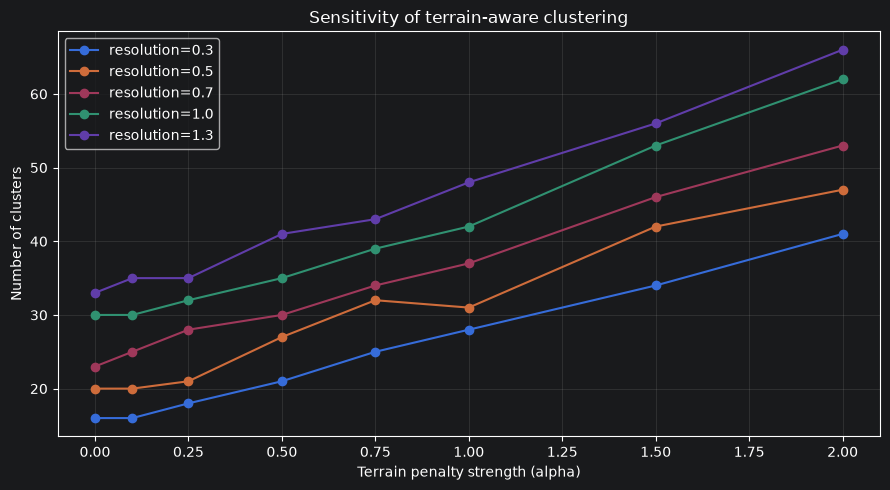

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))

for resolution, group in sensitivity.groupby("resolution"):
    ax.plot(
        group["alpha"],
        group["clusters"],
        marker="o",
        label=f"resolution={resolution}"
    )

ax.set_xlabel("Terrain penalty strength (alpha)")
ax.set_ylabel("Number of clusters")
ax.set_title("Sensitivity of terrain-aware clustering")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [26]:
baseline_communities = nx.community.louvain_communities(
    G_spatial,
    weight="weight",
    resolution=0.3,
    seed=42
)

labels_baseline = communities_to_labels(
    baseline_communities,
    len(peaks)
)

peaks["cluster_spatial_baseline"] = labels_baseline

print("Baseline clusters:", len(baseline_communities))

Baseline clusters: 16


In [27]:
components = sorted(
    [len(c) for c in nx.connected_components(G)],
    reverse=True
)

print("Connected components:", len(components))
print("Largest components:", components[:15])

Connected components: 2
Largest components: [1276, 26]


In [28]:
components = sorted(
    nx.connected_components(G),
    key=len,
    reverse=True
)

small_component = sorted(components[1])

isolated_peaks = peaks.iloc[small_component].copy()

print("Isolated component:", len(isolated_peaks))

display(
    isolated_peaks.groupby("ridge_name")
    .agg(
        peak_count=("id", "count"),
        median_elevation=("elevation_m", "median"),
        max_elevation=("elevation_m", "max")
    )
)

Isolated component: 26


,peak_count,median_elevation,max_elevation
ridge_name,,,
Каржантау,26,2211.6,2823.8


## DEM-based saddle connectivity

### DEM preprocessing

In [29]:
import numpy as np
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from pathlib import Path

# Все вершины уже в EPSG:32642
RESOLUTION = 150  # metres
BUFFER_M = 15_000

xmin, ymin, xmax, ymax = peaks.total_bounds

left = np.floor((xmin - BUFFER_M) / RESOLUTION) * RESOLUTION
bottom = np.floor((ymin - BUFFER_M) / RESOLUTION) * RESOLUTION
right = np.ceil((xmax + BUFFER_M) / RESOLUTION) * RESOLUTION
top = np.ceil((ymax + BUFFER_M) / RESOLUTION) * RESOLUTION

width = int(round((right - left) / RESOLUTION))
height = int(round((top - bottom) / RESOLUTION))

transform = from_origin(
    left, top, RESOLUTION, RESOLUTION
)

cell_count = width * height

print(f"Grid: {width:,} × {height:,}")
print(f"Total cells: {cell_count:,}")
print(f"Resolution: {RESOLUTION} m")
print(f"Raster memory: {cell_count * 4 / 1024**2:.1f} MiB")

assert cell_count <= 10_000_000, (
    "Grid is too large for the initial experiment. "
    "Review the extent or increase resolution."
)

Grid: 1,073 × 1,447
Total cells: 1,552,631
Resolution: 150 m
Raster memory: 5.9 MiB


In [30]:
DEM_DIR = (
    ROOT.parent
    / "day02_lines"
    / "data"
    / "raw"
    / "dem"
)

dem_files = sorted(DEM_DIR.glob("*.tif"))

assert dem_files, "No DEM files found"

# Целевая растровая сетка
dem = np.full(
    (height, width),
    np.nan,
    dtype=np.float32
)

for i, dem_file in enumerate(dem_files, 1):
    with rasterio.open(dem_file) as src:
        tile = np.full_like(dem, np.nan)

        reproject(
            source=rasterio.band(src, 1),
            destination=tile,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs="EPSG:32642",
            dst_nodata=np.nan,
            resampling=Resampling.average
        )

        # Заполняем только ещё пустые ячейки
        mask = np.isfinite(tile) & ~np.isfinite(dem)
        dem[mask] = tile[mask]

    print(f"\rProcessed {i}/{len(dem_files)} tiles", end="")

print("\nDEM coverage:", round(
    np.isfinite(dem).mean() * 100, 2
), "%")

Processed 84/84 tiles
DEM coverage: 100.0 %


In [31]:
DEM_OUT = PROCESSED / "terrain_dem_150m.tif"

profile = {
    "driver": "GTiff",
    "height": height,
    "width": width,
    "count": 1,
    "dtype": "float32",
    "crs": "EPSG:32642",
    "transform": transform,
    "nodata": np.nan,
    "compress": "deflate",
    "predictor": 3,
    "tiled": True
}

with rasterio.open(DEM_OUT, "w", **profile) as dst:
    dst.write(dem, 1)

print("Saved:", DEM_OUT)

Saved: C:\Users\m.maxsudov\30daymapchallenge-2026\projects\day04_clusters\data\processed\terrain_dem_150m.tif


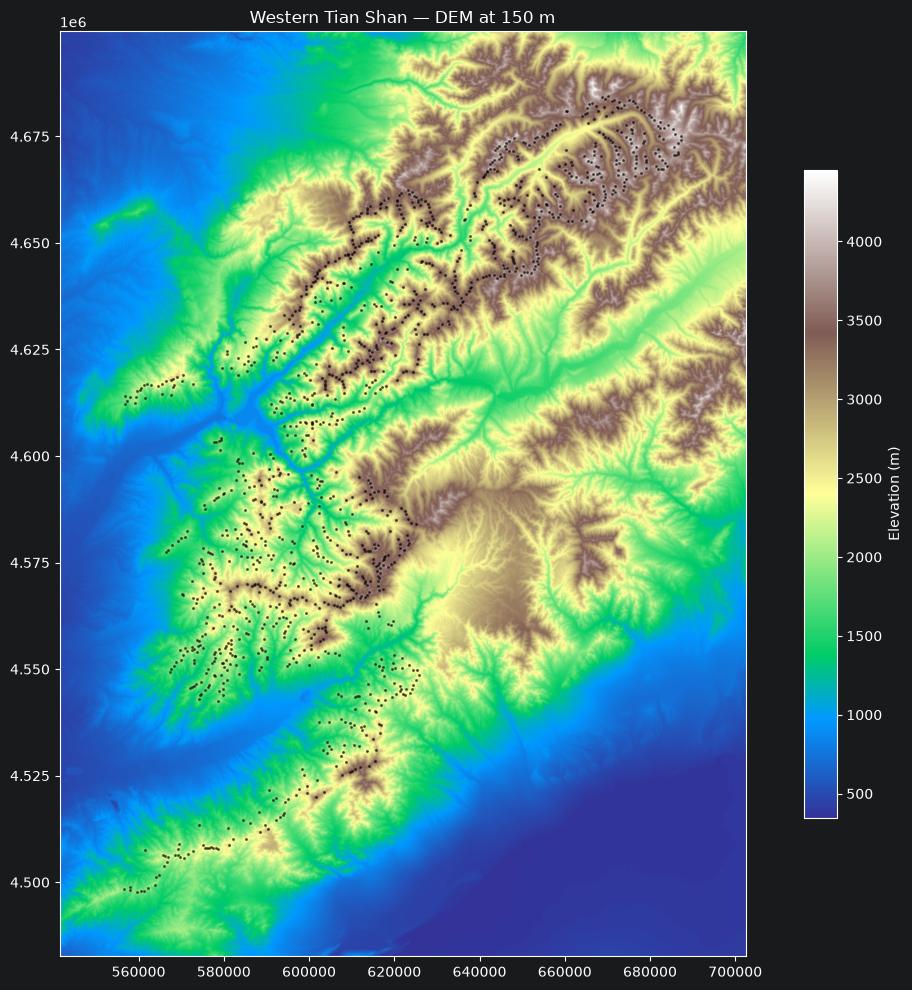

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

extent = [left, right, bottom, top]

im = ax.imshow(
    dem,
    extent=extent,
    origin="upper",
    cmap="terrain"
)

ax.scatter(
    X_xy[:, 0],
    X_xy[:, 1],
    s=1.5,
    color="black",
    alpha=0.5
)

plt.colorbar(
    im,
    ax=ax,
    label="Elevation (m)",
    shrink=0.7
)

ax.set_title("Western Tian Shan — DEM at 150 m")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [33]:
from rasterio.transform import rowcol

rows, cols = rowcol(
    transform,
    X_xy[:, 0],
    X_xy[:, 1]
)

rows = np.asarray(rows)
cols = np.asarray(cols)

inside = (
    (rows >= 0) & (rows < height) &
    (cols >= 0) & (cols < width)
)

valid_peaks = np.zeros(len(peaks), dtype=bool)

idx = np.where(inside)[0]

valid_peaks[idx] = np.isfinite(
    dem[rows[idx], cols[idx]]
)

print("Peaks inside grid:", inside.sum())
print("Peaks with valid DEM:", valid_peaks.sum())
print("Missing peak elevations:", (~valid_peaks).sum())

assert valid_peaks.all(), (
    "Some peaks fall outside valid DEM coverage"
)

Peaks inside grid: 1302
Peaks with valid DEM: 1302
Missing peak elevations: 0


### Расчет Saddles

In [34]:
from scipy import ndimage
import numpy as np
import pandas as pd

edge_list = list(G.edges())

edge_u = np.array([u for u, v in edge_list])
edge_v = np.array([v for u, v in edge_list])

print("Candidate edges:", len(edge_list))
print("DEM shape:", dem.shape)

Candidate edges: 6127
DEM shape: (1447, 1073)


In [35]:
STEP_M = 100

valid_dem = np.isfinite(dem)

min_h = int(np.floor(np.nanmin(dem) / STEP_M) * STEP_M)
max_h = int(np.ceil(np.nanmax(dem) / STEP_M) * STEP_M)

thresholds = np.arange(
    max_h,
    min_h - STEP_M,
    -STEP_M
)

# Седловина для каждой пары
saddle_m = np.full(len(edge_list), np.nan)

# Соседство по 8 направлениям
structure = np.ones((3, 3), dtype=np.uint8)

for threshold in thresholds:
    high_terrain = valid_dem & (dem >= threshold)

    labels, n_components = ndimage.label(
        high_terrain,
        structure=structure
    )

    peak_labels = labels[rows, cols]

    connected = (
        (peak_labels[edge_u] != 0)
        & (peak_labels[edge_u] == peak_labels[edge_v])
    )

    newly_connected = connected & np.isnan(saddle_m)

    saddle_m[newly_connected] = threshold

    print(
        f"\rThreshold {threshold:5.0f} m | "
        f"resolved: {np.isfinite(saddle_m).sum()}/{len(edge_list)}",
        end=""
    )

print("\nFinished.")

Threshold   300 m | resolved: 6127/6127
Finished.


In [36]:
peak_dem_h = dem[rows, cols]

endpoint_min_h = np.minimum(
    peak_dem_h[edge_u],
    peak_dem_h[edge_v]
)

saddle_separation_m = np.maximum(
    0,
    endpoint_min_h - saddle_m
)

saddle_df = pd.DataFrame({
    "u": edge_u,
    "v": edge_v,
    "distance_km": [
        G[u][v]["distance_m"] / 1000
        for u, v in edge_list
    ],
    "saddle_m": saddle_m,
    "saddle_separation_m": saddle_separation_m
})

display(
    saddle_df[
        ["distance_km", "saddle_m", "saddle_separation_m"]
    ].describe(percentiles=[.25, .5, .75, .9, .95]).round(1)
)

print("Unresolved connections:", np.isnan(saddle_m).sum())

,distance_km,saddle_m,saddle_separation_m
count,6127.0,6127.0,6127.0
mean,2.7,2738.8,112.9
std,1.3,721.5,77.5
min,0.0,1500.0,0.2
25%,1.8,2100.0,61.9
50%,2.7,2600.0,97.4
75%,3.5,3400.0,139.2
90%,4.4,3700.0,210.5
95%,5.0,3800.0,267.4
max,8.3,4200.0,729.8


Unresolved connections: 0


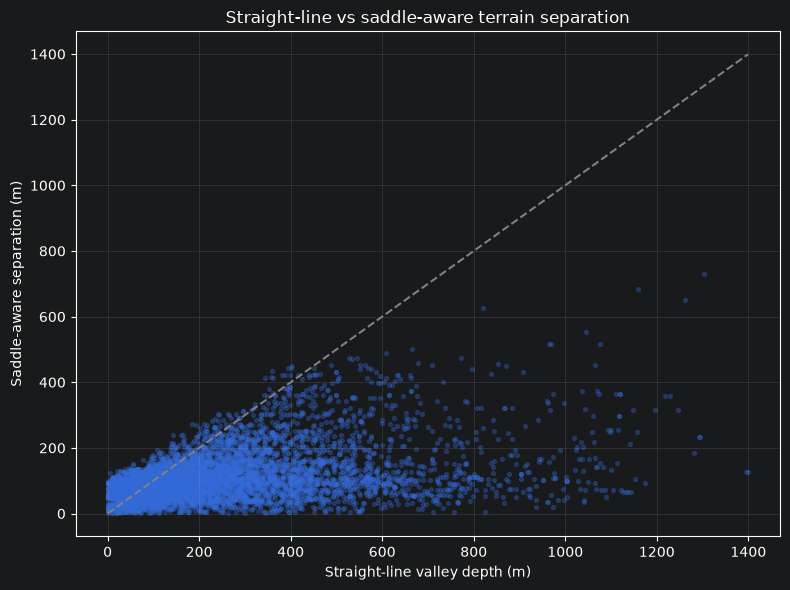

In [37]:
old_valley = np.array([
    G[u][v]["valley_depth_m"]
    for u, v in edge_list
])

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    old_valley,
    saddle_separation_m,
    s=8,
    alpha=0.3
)

limit = max(
    np.nanmax(old_valley),
    np.nanmax(saddle_separation_m)
)

ax.plot([0, limit], [0, limit], "--", color="gray")

ax.set_xlabel("Straight-line valley depth (m)")
ax.set_ylabel("Saddle-aware separation (m)")
ax.set_title("Straight-line vs saddle-aware terrain separation")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Saddle-aware Louvain

In [38]:
import networkx as nx
import numpy as np
import pandas as pd

sigma_d = edges_df["distance_km"].median()

sigma_straight = edges_df.loc[
    edges_df["valley_depth_m"] > 0,
    "valley_depth_m"
].median()

sigma_saddle = np.median(
    saddle_separation_m[saddle_separation_m > 0]
)

print("Distance scale:", sigma_d)
print("Straight-line scale:", sigma_straight)
print("Saddle scale:", sigma_saddle)

assert all(
    np.isfinite(x) and x > 0
    for x in [sigma_d, sigma_straight, sigma_saddle]
)

Distance scale: 2.6603060771235176
Straight-line scale: 206.512451171875
Saddle scale: 97.36181640625


In [39]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

ground_truth = peaks["ridge_id"].astype(int).to_numpy()

methods = {
    "Spatial-only": np.zeros(len(edge_list)),
    "Straight-line terrain": np.array([
        G[u][v]["valley_depth_m"]
        for u, v in edge_list
    ]) / sigma_straight,
    "Saddle-aware terrain": (
        saddle_separation_m / sigma_saddle
    )
}

def run_clustering(method, penalty, alpha=1.0, resolution=0.3):
    graph = G.copy()

    for (u, v), normalized_penalty in zip(
        edge_list, penalty
    ):
        distance_km = graph[u][v]["distance_m"] / 1000

        graph[u][v]["weight"] = float(
            np.exp(-distance_km / sigma_d)
            * np.exp(-alpha * normalized_penalty)
        )

    communities = nx.community.louvain_communities(
        graph,
        weight="weight",
        resolution=resolution,
        seed=42
    )

    labels = communities_to_labels(
        communities,
        len(peaks)
    )

    return {
        "method": method,
        "alpha": alpha,
        "resolution": resolution,
        "clusters": len(communities),
        "ARI": adjusted_rand_score(
            ground_truth, labels
        ),
        "NMI": normalized_mutual_info_score(
            ground_truth, labels
        ),
        "labels": labels
    }

results = [
    run_clustering(
        name,
        penalty,
        alpha=1.0,
        resolution=0.3
    )
    for name, penalty in methods.items()
]

comparison = pd.DataFrame([
    {k: v for k, v in result.items() if k != "labels"}
    for result in results
])

display(comparison.round(3))

,method,alpha,resolution,clusters,ARI,NMI
0,Spatial-only,1.0,0.3,16,0.342,0.684
1,Straight-line terrain,1.0,0.3,28,0.210,0.635
2,Saddle-aware terrain,1.0,0.3,22,0.274,0.633


In [40]:
saddle_results = []

for alpha in [0, 0.1, 0.25, 0.5, 0.75, 1, 1.5, 2]:
    result = run_clustering(
        "Saddle-aware terrain",
        methods["Saddle-aware terrain"],
        alpha=alpha,
        resolution=0.3
    )

    saddle_results.append({
        k: v for k, v in result.items()
        if k != "labels"
    })

display(pd.DataFrame(saddle_results).round(3))

,method,alpha,resolution,clusters,ARI,NMI
0,Saddle-aware terrain,0.00,0.3,16,0.342,0.684
1,Saddle-aware terrain,0.10,0.3,17,0.310,0.672
2,Saddle-aware terrain,0.25,0.3,18,0.310,0.672
3,Saddle-aware terrain,0.50,0.3,19,0.311,0.659
4,Saddle-aware terrain,0.75,0.3,20,0.289,0.649
5,Saddle-aware terrain,1.00,0.3,22,0.274,0.633
6,Saddle-aware terrain,1.50,0.3,24,0.240,0.609
7,Saddle-aware terrain,2.00,0.3,27,0.234,0.620


In [41]:
edge_analysis = pd.DataFrame([
    {
        "u": u,
        "v": v,
        "same_ridge": (
            peaks.iloc[u]["ridge_id"]
            == peaks.iloc[v]["ridge_id"]
        ),
        "distance_km": G[u][v]["distance_m"] / 1000,
        "straight_valley_m": G[u][v]["valley_depth_m"],
        "saddle_separation_m": saddle_separation_m[i]
    }
    for i, (u, v) in enumerate(edge_list)
])

display(
    edge_analysis.groupby("same_ridge")[
        ["distance_km", "straight_valley_m", "saddle_separation_m"]
    ].median().round(1)
)

print(
    "Cross-ridge edges:",
    (~edge_analysis["same_ridge"]).sum()
)

,distance_km,straight_valley_m,saddle_separation_m
same_ridge,,,
False,4.2,774.7,103.0
True,2.6,200.8,97.2


Cross-ridge edges: 158


## Last experiment: Local Saddle Aware

In [42]:
import heapq
import numpy as np

NEIGHBORS = [
    (dr, dc)
    for dr in (-1, 0, 1)
    for dc in (-1, 0, 1)
    if dr != 0 or dc != 0
]

def local_saddle(u, v, corridor_m=2000):
    r1, c1 = int(rows[u]), int(cols[u])
    r2, c2 = int(rows[v]), int(cols[v])

    if r1 == r2 and c1 == c2:
        return float(dem[r1, c1])

    # Размер коридора в пикселях DEM
    radius = corridor_m / RESOLUTION
    margin = int(np.ceil(radius)) + 2

    rmin = max(0, min(r1, r2) - margin)
    rmax = min(dem.shape[0], max(r1, r2) + margin + 1)
    cmin = max(0, min(c1, c2) - margin)
    cmax = min(dem.shape[1], max(c1, c2) + margin + 1)

    tile = dem[rmin:rmax, cmin:cmax]

    # Геометрия коридора в координатах растровой сетки
    rr, cc = np.indices(tile.shape)
    rr = rr + rmin
    cc = cc + cmin

    dx = c2 - c1
    dy = r2 - r1
    length_sq = dx * dx + dy * dy

    t = np.clip(
        ((cc - c1) * dx + (rr - r1) * dy) / length_sq,
        0, 1
    )

    distance_to_segment = np.sqrt(
        (cc - (c1 + t * dx)) ** 2
        + (rr - (r1 + t * dy)) ** 2
    ) * RESOLUTION

    allowed = (
        (distance_to_segment <= corridor_m)
        & np.isfinite(tile)
    )

    start = (r1 - rmin, c1 - cmin)
    target = (r2 - rmin, c2 - cmin)

    best = np.full(tile.shape, -np.inf, dtype=np.float32)

    start_h = float(tile[start])
    best[start] = start_h

    # Max-priority queue: максимизируем минимальную высоту
    queue = [(-start_h, start)]

    while queue:
        neg_score, (r, c) = heapq.heappop(queue)
        score = -neg_score

        if score < best[r, c]:
            continue

        if (r, c) == target:
            return float(score)

        for dr, dc in NEIGHBORS:
            nr, nc = r + dr, c + dc

            if not (
                0 <= nr < tile.shape[0]
                and 0 <= nc < tile.shape[1]
            ):
                continue

            if not allowed[nr, nc]:
                continue

            candidate = min(score, float(tile[nr, nc]))

            if candidate > best[nr, nc]:
                best[nr, nc] = candidate
                heapq.heappush(
                    queue,
                    (-candidate, (nr, nc))
                )

    return np.nan

In [43]:
test_edges = edge_list[:5]

for u, v in test_edges:
    values = {
        width: local_saddle(u, v, corridor_m=width)
        for width in [1000, 2000, 3000]
    }

    print(f"Edge {u}-{v}: {values}")

Edge 0-23: {1000: 2457.251708984375, 2000: 2457.251708984375, 3000: 2457.251708984375}
Edge 0-21: {1000: 2172.760498046875, 2000: 2172.760498046875, 3000: 2172.760498046875}
Edge 0-24: {1000: 2457.251708984375, 2000: 2457.251708984375, 3000: 2457.251708984375}
Edge 0-11: {1000: 1905.62109375, 2000: 1905.62109375, 3000: 1905.62109375}
Edge 0-22: {1000: 2150.958740234375, 2000: 2150.958740234375, 3000: 2150.958740234375}


In [44]:
corridor_widths = [1000, 2000, 3000]
local_saddles = {}

for width in corridor_widths:
    values = np.full(len(edge_list), np.nan)

    for i, (u, v) in enumerate(edge_list):
        values[i] = local_saddle(
            u, v,
            corridor_m=width
        )

        if (i + 1) % 500 == 0:
            print(
                f"Width {width} m: "
                f"{i+1}/{len(edge_list)}"
            )

    local_saddles[width] = values

    print(
        f"Corridor {width} m | "
        f"Unresolved: {np.isnan(values).sum()}"
    )

Width 1000 m: 500/6127
Width 1000 m: 1000/6127
Width 1000 m: 1500/6127
Width 1000 m: 2000/6127
Width 1000 m: 2500/6127
Width 1000 m: 3000/6127
Width 1000 m: 3500/6127
Width 1000 m: 4000/6127
Width 1000 m: 4500/6127
Width 1000 m: 5000/6127
Width 1000 m: 5500/6127
Width 1000 m: 6000/6127
Corridor 1000 m | Unresolved: 0
Width 2000 m: 500/6127
Width 2000 m: 1000/6127
Width 2000 m: 1500/6127
Width 2000 m: 2000/6127
Width 2000 m: 2500/6127
Width 2000 m: 3000/6127
Width 2000 m: 3500/6127
Width 2000 m: 4000/6127
Width 2000 m: 4500/6127
Width 2000 m: 5000/6127
Width 2000 m: 5500/6127
Width 2000 m: 6000/6127
Corridor 2000 m | Unresolved: 0
Width 3000 m: 500/6127
Width 3000 m: 1000/6127
Width 3000 m: 1500/6127
Width 3000 m: 2000/6127
Width 3000 m: 2500/6127
Width 3000 m: 3000/6127
Width 3000 m: 3500/6127
Width 3000 m: 4000/6127
Width 3000 m: 4500/6127
Width 3000 m: 5000/6127
Width 3000 m: 5500/6127
Width 3000 m: 6000/6127
Corridor 3000 m | Unresolved: 0


In [45]:
local_separations = {}

endpoint_min_h = np.minimum(
    peak_dem_h[edge_u],
    peak_dem_h[edge_v]
)

for width, saddles in local_saddles.items():
    local_separations[width] = np.maximum(
        0,
        endpoint_min_h - saddles
    )

    print(
        f"{width} m corridor:",
        np.nanmedian(local_separations[width])
    )

1000 m corridor: 56.9091796875
2000 m corridor: 45.759033203125
3000 m corridor: 42.684326171875


In [46]:
diagnostics = []

for width, separation in local_separations.items():
    df = edge_analysis.copy()
    df["separation"] = separation

    within = df.loc[df["same_ridge"], "separation"]
    cross = df.loc[~df["same_ridge"], "separation"]

    diagnostics.append({
        "corridor_m": width,
        "within_median": within.median(),
        "cross_median": cross.median(),
        "ratio": cross.median() / max(within.median(), 1e-9),
        "missing": df["separation"].isna().sum()
    })

diagnostic_df = pd.DataFrame(diagnostics)

display(diagnostic_df.round(2))

,corridor_m,within_median,cross_median,ratio,missing
0,1000,54.64,690.82,12.64,0
1,2000,43.86,648.19,14.78,0
2,3000,40.47,612.85,15.14,0


In [47]:
local_results = []

for width, separation in local_separations.items():
    assert np.isfinite(separation).all(), (
        f"Missing values for corridor {width}"
    )

    positive = separation[separation > 0]
    sigma_local = np.median(positive)

    assert np.isfinite(sigma_local) and sigma_local > 0

    result = run_clustering(
        method=f"Local saddle {width}m",
        penalty=separation / sigma_local,
        alpha=1.0,
        resolution=0.3
    )

    local_results.append(result)

local_comparison = pd.DataFrame([
    {
        k: v for k, v in result.items()
        if k != "labels"
    }
    for result in local_results
])

display(local_comparison.round(3))

,method,alpha,resolution,clusters,ARI,NMI
0,Local saddle 1000m,1.0,0.3,40,0.181,0.618
1,Local saddle 2000m,1.0,0.3,37,0.222,0.637
2,Local saddle 3000m,1.0,0.3,32,0.265,0.659


In [48]:
final_comparison = pd.concat(
    [comparison, local_comparison],
    ignore_index=True
)

display(
    final_comparison[
        ["method", "clusters", "ARI", "NMI"]
    ].sort_values("ARI", ascending=False).round(3)
)

,method,clusters,ARI,NMI
0,Spatial-only,16,0.342,0.684
2,Saddle-aware terrain,22,0.274,0.633
5,Local saddle 3000m,32,0.265,0.659
4,Local saddle 2000m,37,0.222,0.637
1,Straight-line terrain,28,0.210,0.635
3,Local saddle 1000m,40,0.181,0.618


## Final Export

In [49]:
# Собираем готовые кластерные метки
cluster_outputs = {
    result["method"]: result["labels"]
    for result in results + local_results
}

# Безопасные имена полей GeoPackage
field_names = {
    "Spatial-only": "cluster_spatial",
    "Straight-line terrain": "cluster_straight",
    "Saddle-aware terrain": "cluster_global",
    "Local saddle 1000m": "cluster_local_1km",
    "Local saddle 2000m": "cluster_local_2km",
    "Local saddle 3000m": "cluster_local_3km"
}

peaks_export = peaks.copy()

for method, labels in cluster_outputs.items():
    peaks_export[field_names[method]] = labels

assert len(peaks_export) == 1302
assert peaks_export["id"].is_unique

peaks_export.to_file(
    PROCESSED / "peaks_clustered.gpkg",
    layer="peak_clusters",
    driver="GPKG"
)

final_comparison.to_csv(
    PROCESSED / "clustering_comparison.csv",
    index=False
)

In [50]:
np.savez_compressed(
    PROCESSED / "saddle_metrics.npz",
    edge_u=edge_u,
    edge_v=edge_v,
    global_saddle=saddle_m,
    local_1km=local_saddles[1000],
    local_2km=local_saddles[2000],
    local_3km=local_saddles[3000]
)